<div style="background-color:#000;"><img src="pqn.png"></img></div><div><a href="https://pyquantnews.com/">PyQuant News</a> is where finance practitioners level up with Python for quant finance, algorithmic trading, and market data analysis. Looking to get started? Check out the fastest growing, top-selling course to <a href="https://www.pyquantnews.com/getting-started-with-python-for-quant-finance/">get started with Python for quant finance</a>. For educational purposes. Not investment advice. Use at your own risk.</div>

## Library installation

This installs the libraries needed to run the notebook.

In [ ]:
!pip install numpy matplotlib

## Imports and setup

numpy handles the vectorized math behind our Monte Carlo simulation, and matplotlib produces the visualization of simulated stock price paths.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Simulate stock prices with geometric Brownian motion

This function generates 1,000 simulated stock price paths using geometric Brownian motion (GBM), the standard model for how stock prices evolve over time.

In [2]:
def simulate_gbm(s_0, mu, sigma, T, N, n_sims=10**3, random_seed=1):
    """Simulate stock returns using Geometric Brownian Motion."""

    np.random.seed(random_seed)

    dt = T / N

    dW = np.random.normal(scale=np.sqrt(dt), size=(n_sims, N + 1))

    S_t = s_0 * np.exp(
        np.cumsum(
            (mu - 0.5 * sigma**2) * dt + sigma * dW, axis=1
        )
    )
    S_t[:, 0] = s_0

    return S_t

GBM works by accumulating small random shocks (dW) at each time step, then exponentiating the cumulative sum so prices stay positive, just like real stock prices. The drift term (mu - 0.5 * sigma**2) corrects for the fact that log-returns and arithmetic returns differ, a subtlety that trips up many beginners. By generating all 1,000 paths in a single numpy array instead of looping, we keep the simulation fast and ready to scale to millions of paths if needed.

We define the option contract parameters here. S_0 is the starting stock price, r is the risk-free rate used for both drift and discounting, sigma is annualized volatility, T is time to expiration in years, and N is the number of daily trading steps.

In [3]:
S_0 = 55
r = 0.06
sigma = 0.2
T = 1
N = 252

In [4]:
BARRIER = 65
K = 60

The barrier (65) is the price level the stock must cross for the option to activate, and K (60) is the strike price used to calculate the payoff at expiration. Notice the barrier is above both the starting price and the strike. This is what makes it an "Up-and-In" option: the contract is worthless unless the stock rallies past 65 at some point, even if it finishes above the strike.

## Visualize simulated price paths

This runs the simulation and plots all 1,000 paths alongside the barrier level so we can visually inspect how many paths cross the activation threshold.

In [5]:
gbm_sims = simulate_gbm(s_0=S_0, mu=r, sigma=sigma, T=T, N=N)

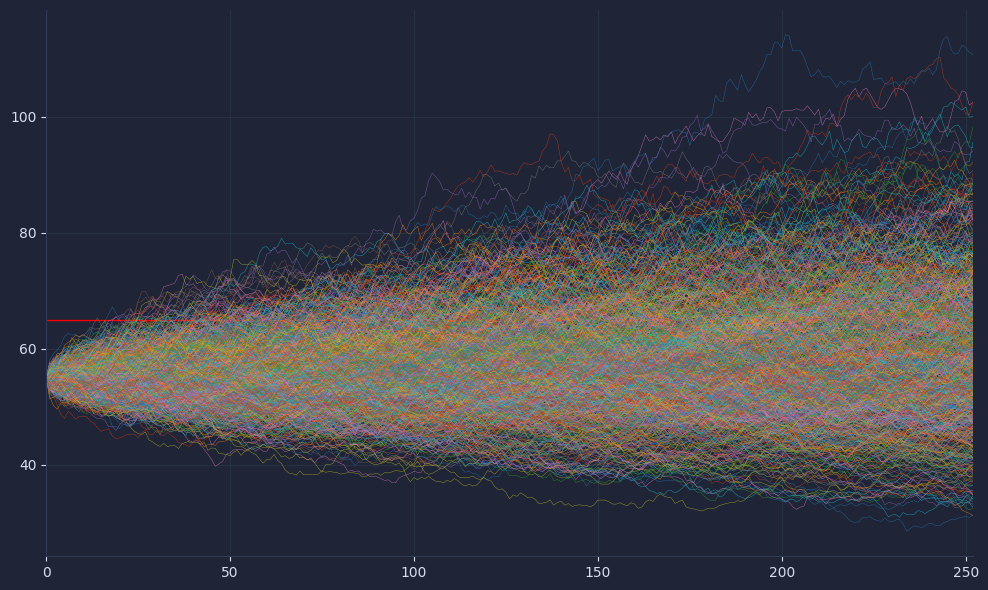

In [6]:
plt.axhline(y=BARRIER, color='r', linestyle='-')
plt.xlim(0, N)
plt.plot(gbm_sims.T, linewidth=0.25)
plt.show()

The red horizontal line marks the barrier at 65. Paths that touch or cross it at any point during the year are the only ones that can produce a payoff. This kind of visual check is exactly what professional quant teams do before trusting their simulation output. If most paths cluster well below the barrier, we'd expect a low option price, and the plot lets us confirm that intuition before running the numbers.

## Price the up-and-in barrier call option

We find the maximum price reached along each path to determine which simulations triggered the barrier condition.

In [7]:
max_value_per_path = np.max(gbm_sims, axis=1)

This single line is what makes barrier options path-dependent. A standard European call only looks at the final price, but here we need the entire history of each path to check whether the stock ever breached 65. That distinction between "where did it end up" and "where did it go along the way" is the core concept this tutorial is built around.

For each path that crossed the barrier, we compute the standard call payoff (final price minus strike, floored at zero). Paths that never crossed the barrier get a payoff of zero regardless of where they finished.

In [8]:
payoff = np.where(
    max_value_per_path > BARRIER,
    np.maximum(0, gbm_sims[:, -1] - K),
    0
)

np.where acts as our conditional filter, applying two rules in one vectorized operation. First, did the path ever cross the barrier? Second, if so, is the final price above the strike? A path could cross the barrier mid-year but finish below the strike, producing zero payoff even though the option activated. This two-layer logic is what separates barrier option pricing from vanilla option pricing.

We discount the average payoff back to today's value using the risk-free rate to get the fair premium for this Up-and-In barrier call.

In [9]:
discount_factor = np.exp(-r * T)
premium = discount_factor * np.mean(payoff)
premium

np.float64(4.019441670553388)

Discounting converts a future expected dollar amount into what it's worth right now, which is how every financial contract is priced. We use continuous compounding (exp(-r * T)) because that matches the GBM model we used to simulate the paths. The final number is our Monte Carlo estimate of the option's fair value, the same approach that derivatives desks use daily, just with more paths and additional refinements like variance reduction.

<a href="https://pyquantnews.com/">PyQuant News</a> is where finance practitioners level up with Python for quant finance, algorithmic trading, and market data analysis. Looking to get started? Check out the fastest growing, top-selling course to <a href="https://www.pyquantnews.com/getting-started-with-python-for-quant-finance/">get started with Python for quant finance</a>. For educational purposes. Not investment advice. Use at your own risk.